# Binning Discretization 

# 

In [42]:
import numpy as np
import pandas as pd


In [43]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score

from sklearn.preprocessing import KBinsDiscretizer
from sklearn.compose import ColumnTransformer

In [44]:
df=pd.read_csv("Titanic.csv",usecols=['Age','Fare','Survived'])

In [45]:
# drop missing value rows
df.dropna(inplace=True)

In [46]:
df.shape

(714, 3)

In [47]:
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [48]:
x=df.iloc[:,1:]   #df.iloc[row_start:row_end, column_start:column_end]
y=df.iloc[:,0]

In [49]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [50]:
x_train.head(3)

,Age,Fare
328,31.0,20.5250
73,26.0,14.4542
253,30.0,16.1000


In [51]:
clf=DecisionTreeClassifier()

In [52]:
clf.fit(x_train,y_train)
y_pred=clf.predict(x_test)

In [53]:
# actual data  and predict data me compare and he will be give accuracy.
accuracy_score(y_test,y_pred)

0.6223776223776224

In [54]:
np.mean(cross_val_score(DecisionTreeClassifier(),x,y,cv=10,scoring='accuracy'))

np.float64(0.6372848200312988)

In [55]:
kbin_age=KBinsDiscretizer(n_bins=15,encode='ordinal',strategy='quantile')
kbin_fare=KBinsDiscretizer(n_bins=15,encode='ordinal',strategy='quantile')


In [56]:
trf=ColumnTransformer([
    ('first',kbin_age,[0]),
    ('second',kbin_fare,[1])
])

In [57]:
# fit()=It learns information from training data.(mean, standard deviation)
# transform()= It applies that learning.

x_train_trf= trf.fit_transform(x_train)

x_test_trf= trf.transform(x_test)

C:\Users\Alok Kumar\AppData\Roaming\Python\Python313\site-packages\sklearn\preprocessing\_discretization.py:296: FutureWarning: The current default behavior, quantile_method='linear', will be changed to quantile_method='averaged_inverted_cdf' in scikit-learn version 1.9 to naturally support sample weight equivalence properties by default. Pass quantile_method='averaged_inverted_cdf' explicitly to silence this warning.
  warnings.warn(
C:\Users\Alok Kumar\AppData\Roaming\Python\Python313\site-packages\sklearn\preprocessing\_discretization.py:296: FutureWarning: The current default behavior, quantile_method='linear', will be changed to quantile_method='averaged_inverted_cdf' in scikit-learn version 1.9 to naturally support sample weight equivalence properties by default. Pass quantile_method='averaged_inverted_cdf' explicitly to silence this warning.
  warnings.warn(


In [58]:
trf.named_transformers_

{'first': KBinsDiscretizer(encode='ordinal', n_bins=15),
 'second': KBinsDiscretizer(encode='ordinal', n_bins=15)}

In [59]:
trf.named_transformers_['first'].n_bins  

15

In [60]:
# trf.named_transformers_['first'].bin_edges_
trf.named_transformers_['second'].bin_edges_


array([array([  0.    ,   7.25  ,   7.775 ,   7.8958,   8.1583,  10.5   ,
               13.    ,  14.4542,  18.75  ,  26.    ,  26.55  ,  31.275 ,
               51.4792,  76.2917, 108.9   , 512.3292])                   ],
      dtype=object)

In [61]:
output= pd.DataFrame({
    'age':x_train["Age"],
    'age_trf':x_train_trf[:,0],
    'fare':x_train['Fare'],
    'fare_trf':x_train_trf[:,1]

})

In [62]:
output['age_labels']= pd.cut(x=x_train["Age"],
                             bins=trf.named_transformers_['first'].bin_edges_[0].tolist())

output['fare_labels'] = pd.cut(x=x_train["Fare"],
                               bins=trf.named_transformers_['second'].bin_edges_[0].tolist())

In [63]:
output.sample(5)

,age,age_trf,fare,fare_trf,age_labels,fare_labels
280,65.0,14.0,7.7500,1.0,"(54.0, 80.0]","(7.25, 7.775]"
139,24.0,5.0,79.2000,13.0,"(23.0, 25.0]","(76.292, 108.9]"
623,21.0,4.0,7.8542,2.0,"(19.0, 21.0]","(7.775, 7.896]"
275,63.0,14.0,77.9583,13.0,"(54.0, 80.0]","(76.292, 108.9]"
801,31.0,8.0,26.2500,9.0,"(30.0, 32.0]","(26.0, 26.55]"


In [64]:
clf=DecisionTreeClassifier()
clf.fit(x_train_trf,y_train)
y_pred2 = clf.predict(x_test_trf)

In [65]:
accuracy_score(y_test,y_pred2)

0.6363636363636364

In [75]:
x_trf = trf.fit_transform(x)
np.mean(cross_val_score(DecisionTreeClassifier(),x,y,cv=10,scoring='accuracy'))

C:\Users\Alok Kumar\AppData\Roaming\Python\Python313\site-packages\sklearn\preprocessing\_discretization.py:296: FutureWarning: The current default behavior, quantile_method='linear', will be changed to quantile_method='averaged_inverted_cdf' in scikit-learn version 1.9 to naturally support sample weight equivalence properties by default. Pass quantile_method='averaged_inverted_cdf' explicitly to silence this warning.
  warnings.warn(
C:\Users\Alok Kumar\AppData\Roaming\Python\Python313\site-packages\sklearn\preprocessing\_discretization.py:296: FutureWarning: The current default behavior, quantile_method='linear', will be changed to quantile_method='averaged_inverted_cdf' in scikit-learn version 1.9 to naturally support sample weight equivalence properties by default. Pass quantile_method='averaged_inverted_cdf' explicitly to silence this warning.
  warnings.warn(


np.float64(0.6289123630672926)

In [78]:
# from sklearn.preprocessing import KBinsDiscretizer
# from sklearn.compose import ColumnTransformer
# from sklearn.tree import DecisionTreeClassifier
# from sklearn.model_selection import cross_val_score

# import matplotlib.pyplot as plt
# import numpy as np


def discretize(bins, strategy):
    kbin_age = KBinsDiscretizer(
        n_bins=bins,
        encode='ordinal',
        strategy=strategy
    )

    kbin_fare = KBinsDiscretizer(
        n_bins=bins,
        encode='ordinal',
        strategy=strategy
    )

    trf = ColumnTransformer([
        ('first', kbin_age, [0]),
        ('second', kbin_fare, [1])
    ])

    x_trf = trf.fit_transform(x)

    print(np.mean(
        cross_val_score(
            DecisionTreeClassifier(),
            x,
            y,
            cv=10,
            scoring='accuracy'
        )
    ))

    plt.figure(figsize=(14,4))

    plt.subplot(121)
    plt.hist(x['Age'])
    plt.title('Age Before')

    plt.subplot(122)
    plt.hist(x_trf[:,0], color='red')
    plt.title('Age After')


    plt.figure(figsize=(14,4))

    plt.subplot(121)
    plt.hist(x['Fare'])
    plt.title('Fare Before')

    plt.subplot(122)
    plt.hist(x_trf[:,1], color='red')
    plt.title('Fare After')

    plt.show()




accuracy:
0.6331377151799686


C:\Users\Alok Kumar\AppData\Roaming\Python\Python313\site-packages\sklearn\preprocessing\_discretization.py:296: FutureWarning: The current default behavior, quantile_method='linear', will be changed to quantile_method='averaged_inverted_cdf' in scikit-learn version 1.9 to naturally support sample weight equivalence properties by default. Pass quantile_method='averaged_inverted_cdf' explicitly to silence this warning.
  warnings.warn(
C:\Users\Alok Kumar\AppData\Roaming\Python\Python313\site-packages\sklearn\preprocessing\_discretization.py:296: FutureWarning: The current default behavior, quantile_method='linear', will be changed to quantile_method='averaged_inverted_cdf' in scikit-learn version 1.9 to naturally support sample weight equivalence properties by default. Pass quantile_method='averaged_inverted_cdf' explicitly to silence this warning.
  warnings.warn(


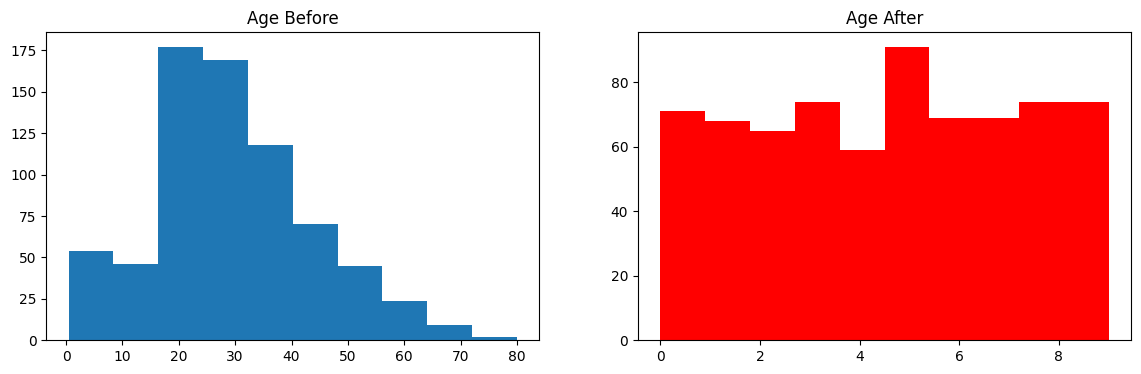

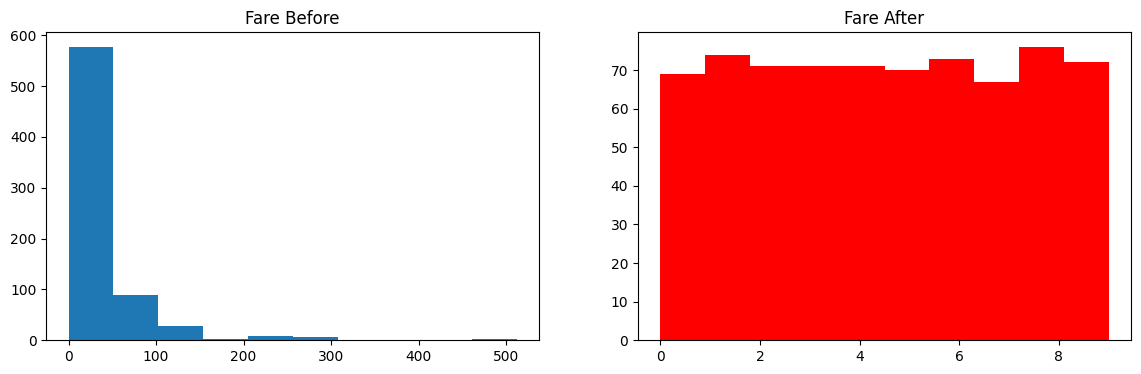

In [79]:
# after quantile accuracy
print("accuracy:")
discretize(10,'quantile')

0.6303012519561815


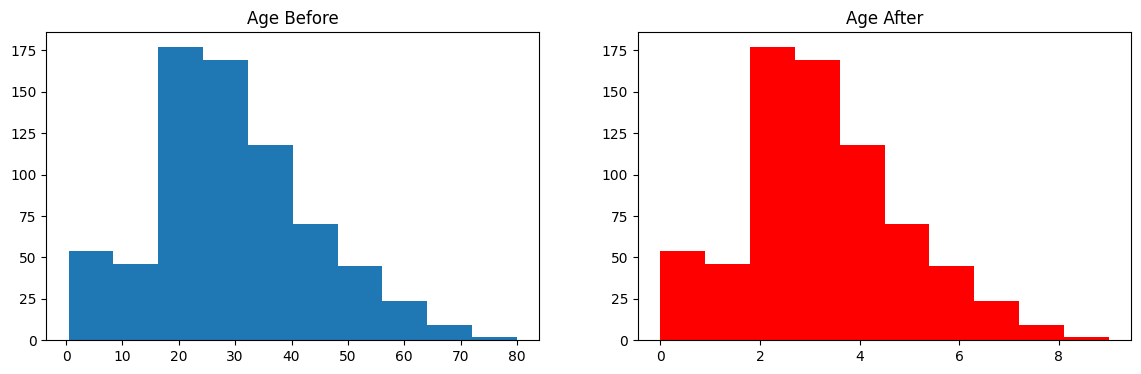

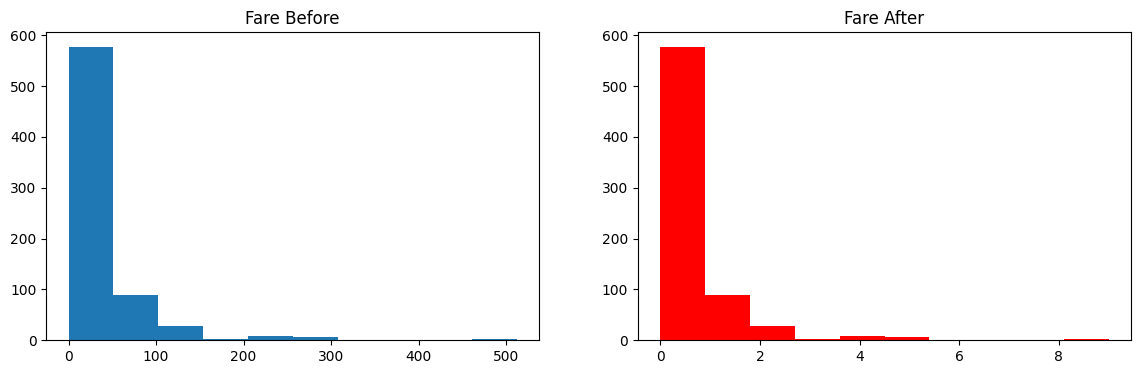

In [80]:
discretize(10,'uniform')


0.6303403755868543


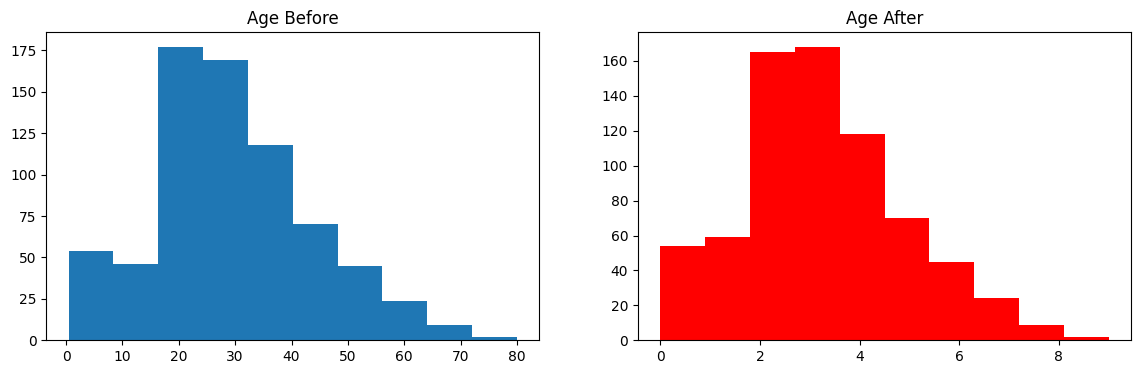

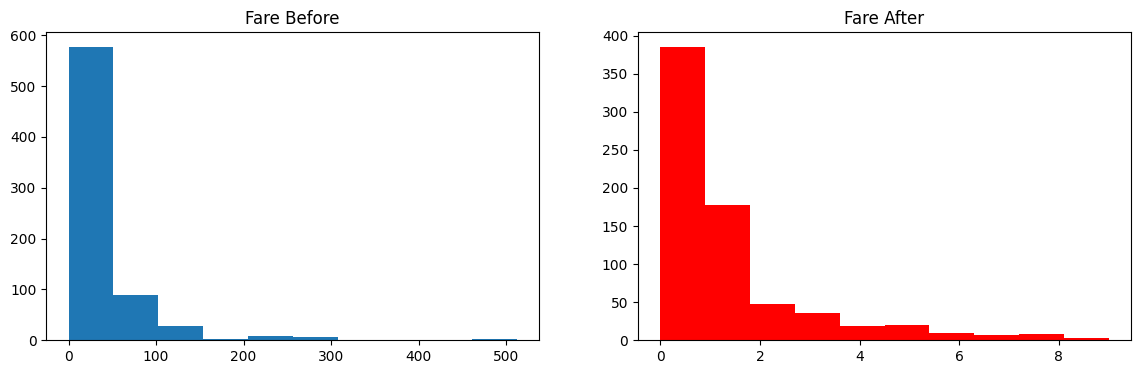

In [82]:
discretize(10,'kmeans')
